# 04 · Além do OEE: MTBF, MTTR e a família TEEP, OAE, OOE, OPE e OFE

**Objetivo:** calcular, a partir dos mesmos dados coletados, os indicadores de confiabilidade e os parentes do OEE, entender o que cada um mede e conferir tudo contra a verdade de uma semana simulada.

## Antes de começar

- **Você precisa de:** o notebook 03 (OEE a partir de estados e contadores).
- **Tempo:** 30 minutos.
- **Broker:** nenhum.
- **Referência:** [docs/indicators.md](../docs/indicators.md) tem as fórmulas exatas e as fontes.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline

## 1. O dado que faltava: por que a máquina parou

Até o notebook 03 o nó só dizia "rodando" ou "parada". Para separar quebra de almoço, o `state` ganhou dois campos opcionais:

| Campo | Valores |
|---|---|
| `category` | `closed`, `unscheduled`, `planned`, `failure`, `unplanned` |
| `reason` | `meal`, `changeover`, `preventive`, `jam`, `seal-wear`, `no-material`... |

Na prática, o motivo vem do operador no painel ou de um código de falha do CLP. O contrato continua v1: quem ignora os campos novos segue funcionando.

In [2]:
from oeelab.contract import validate
base = {"v":1, "seq":88, "boot":"a1b2c3", "value":0, "running":False}
for nome, p in {"falha com modo": {**base, "category":"failure", "reason":"seal-wear"},
                "categoria inventada": {**base, "category":"quebrou"},
                "motivo fora do padrão": {**base, "reason":"Seal Wear"}}.items():
    e = validate("state", p)
    print(f"{nome:22s} {'OK' if not e else 'RECUSADO: ' + e[0][:70]}")

falha com modo         OK
categoria inventada    RECUSADO: category: 'quebrou' is not one of ['closed', 'unscheduled', 'planned',
motivo fora do padrão  RECUSADO: reason: 'Seal Wear' does not match '^[a-z0-9]+(-[a-z0-9]+)*$'


## 2. A semana

`oeelab.week` simula uma semana de três máquinas em duas linhas:

| | Linha 1 (enchedora e tampadora) | Linha 2 (prensa) |
|---|---|---|
| Segunda a sexta | 3 turnos | 2 turnos |
| Sábado | 1 turno | sem turno |
| Domingo | fábrica fechada | fábrica fechada |
| Em todo turno | almoço de 30 min | almoço de 30 min |
| Turno A | troca de formato de 25 min | troca de formato de 25 min |
| Quarta, turno A | preventiva de 2 h | preventiva de 2 h |

As falhas são sorteadas com um MTBF próprio de cada máquina, e cada modo de falha tem seu tempo médio de reparo. Toda parada é publicada com categoria e motivo, passa pelo coletor e vira linha no banco.

In [3]:
from oeelab.weeklab import run_week, lines
medido, verdade, coletor = run_week()

h = 3600
print(f"{'máquina':10s} {'rodando':>8s} {'planej.':>8s} {'falha':>7s} {'outras':>7s} {'sem turno':>10s} {'fechada':>8s} {'total':>7s}")
for nome, t in medido.items():
    s = t.seconds
    print(f"{nome:10s} {s['run']/h:8.1f} {s['planned']/h:8.1f} {s['failure']/h:7.1f} {s['unplanned']/h:7.1f} "
          f"{s['unscheduled']/h:10.1f} {s['closed']/h:8.1f} {sum(s.values())/h:7.1f}")
print("\nmensagens recusadas:", coletor.rows("SELECT COUNT(*) n FROM dlq")[0]["n"])

máquina     rodando  planej.   falha  outras  sem turno  fechada   total
filler-01     107.6     12.5     6.1     1.8       16.0     24.0   168.0
capper-01     108.8     12.5     6.3     0.4       16.0     24.0   168.0
press-02       68.7      9.1     1.9     0.3       64.0     24.0   168.0

mensagens recusadas: 0


Cada segundo das 168 horas cai em exatamente um balde. É essa contabilidade completa que permite comparar os indicadores.

## 3. MTBF e MTTR

### Pare e preveja

Sem a categoria, tudo o que se sabe é "parou". Se você calcular o tempo médio entre paradas e a duração média de parada misturando almoço, troca de formato e quebra, o resultado fica **maior ou menor** que o MTBF e o MTTR de verdade?

In [4]:
from oeelab.week import FLEET
for nome, t in medido.items():
    paradas = coletor.rows("SELECT COUNT(*) n FROM states WHERE machine=? AND running=0 AND category IN ('planned','failure','unplanned')",
                           FLEET[nome][0].base)[0]["n"]
    tempo_parado = t.seconds["planned"] + t.seconds["failure"] + t.seconds["unplanned"]
    print(f"{nome:10s} sem categoria: entre paradas {t.seconds['run']/paradas/h:5.2f} h, parada média {tempo_parado/paradas/60:5.1f} min "
          f"| com categoria: MTBF {t.mtbf_h:5.2f} h, MTTR {t.mttr_min:5.1f} min, falhas {len(t.failures)}")

filler-01  sem categoria: entre paradas  2.34 h, parada média  26.6 min | com categoria: MTBF  5.66 h, MTTR  19.2 min, falhas 19
capper-01  sem categoria: entre paradas  2.65 h, parada média  28.1 min | com categoria: MTBF  6.40 h, MTTR  22.2 min, falhas 17
press-02   sem categoria: entre paradas  3.44 h, parada média  33.9 min | com categoria: MTBF 22.90 h, MTTR  37.6 min, falhas 3


Sem a categoria, a máquina parece quebrar **de duas a sete vezes mais** do que quebra de fato, porque cada almoço e cada troca de formato contam como "falha". O MTTR aparente também fica distorcido. Um plano de manutenção feito em cima desses números atacaria o problema errado.

Por modo de falha, o mesmo cálculo aponta o que corrigir primeiro:

In [5]:
for nome, t in medido.items():
    print(nome)
    for modo, d in sorted(t.by_mode().items(), key=lambda kv: -kv[1]["downtime_min"]):
        print(f"   {modo:18s} {d['failures']:3d} falhas  {d['downtime_min']:6.0f} min parada  MTTR {d['mttr_min']:5.1f} min")

filler-01
   jam                 14 falhas     163 min parada  MTTR  11.7 min
   sensor-fault         3 falhas     131 min parada  MTTR  43.7 min
   seal-wear            2 falhas      70 min parada  MTTR  35.2 min
capper-01
   torque-head          5 falhas     267 min parada  MTTR  53.3 min
   sensor-fault         5 falhas      68 min parada  MTTR  13.5 min
   jam                  7 falhas      42 min parada  MTTR   6.1 min
press-02
   hydraulic-leak       1 falhas      92 min parada  MTTR  91.8 min
   jam                  2 falhas      21 min parada  MTTR  10.5 min


Repare que o modo mais frequente nem sempre é o que mais tira tempo. Uma falha rara e demorada pode custar mais que dez travamentos rápidos. Por isso o ranking por **tempo parado** vem antes do ranking por contagem.

## 4. A família do OEE: o mesmo numerador, quatro denominadores

Todos são `peças boas × ciclo ideal ÷ tempo de referência`. Só o tempo de referência muda:

| Indicador | Tempo de referência |
|---|---|
| TEEP | calendário inteiro |
| OAE | calendário menos fábrica fechada |
| OOE | menos o tempo sem turno programado |
| OEE | menos as paradas planejadas |

### Pare e preveja

A prensa trabalha só dois turnos e a linha 1 trabalha três. Qual máquina tem o maior OEE? E o maior TEEP?

máquina      TEEP    OAE    OOE    OEE   (medido = verdade?)
filler-01   53.4%  62.3%  70.0%  77.6%   True
capper-01   54.3%  63.3%  71.3%  79.0%   True
press-02    34.2%  39.9%  71.9%  81.1%   True


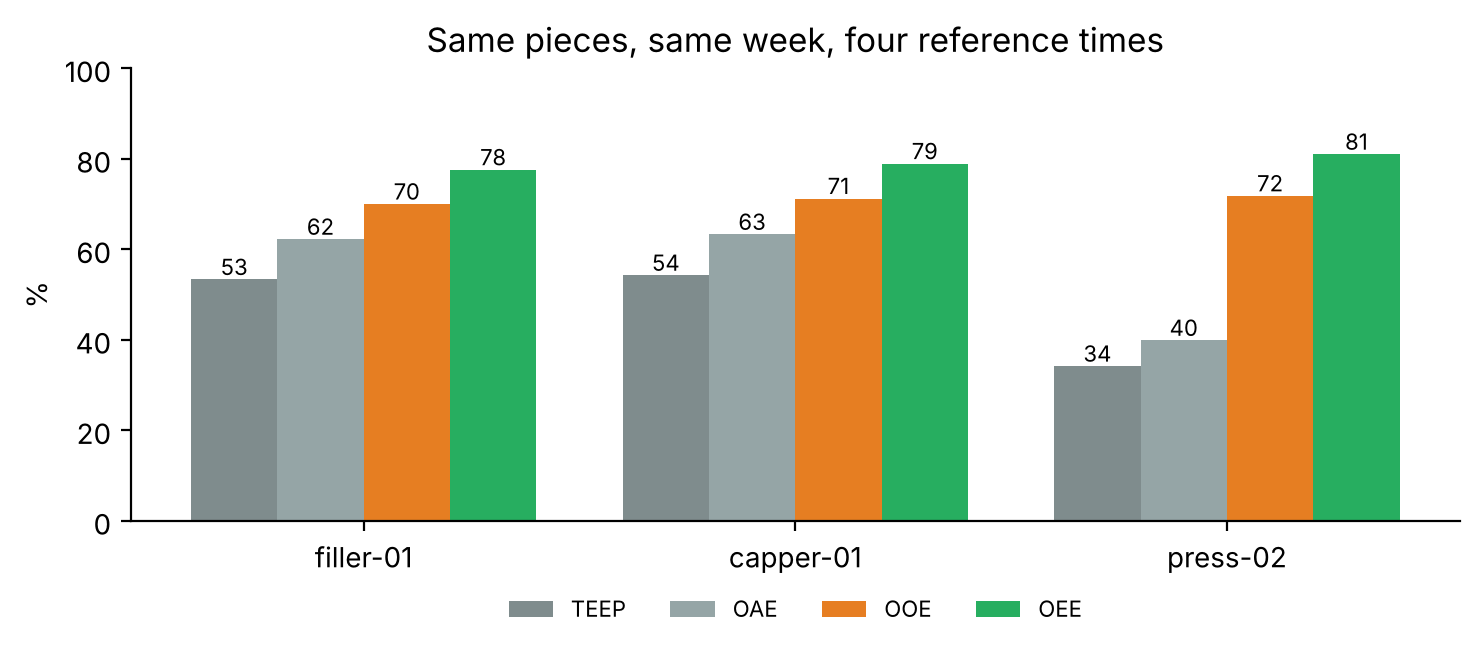

In [6]:
print(f"{'máquina':10s} {'TEEP':>6s} {'OAE':>6s} {'OOE':>6s} {'OEE':>6s}   (medido = verdade?)")
for nome, t in medido.items():
    v = verdade[nome]
    iguais = all(abs(t.indicator(k) - v.indicator(k)) < 1e-9 for k in ("TEEP","OAE","OOE","OEE"))
    print(f"{nome:10s} " + " ".join(f"{t.indicator(k):6.1%}" for k in ("TEEP","OAE","OOE","OEE")) + f"   {iguais}")
from oeelab import figures
figures.family();

A prensa tem o **maior OEE** e o **menor TEEP**. As duas coisas são verdade ao mesmo tempo:

- **OEE** diz que, nas horas em que foi planejado produzir, a prensa foi bem usada.
- **TEEP** diz que a prensa fica parada a maior parte da semana porque não há turno para ela.

São perguntas diferentes. O OEE serve para o supervisor do turno melhorar a operação. O TEEP serve para decidir investimento: antes de comprar uma prensa nova, existe capacidade sobrando na que já está lá, bastaria um terceiro turno.

A cascata mostra onde cada hora da semana da prensa foi parar, com cada indicador marcado no degrau em que ele mede:

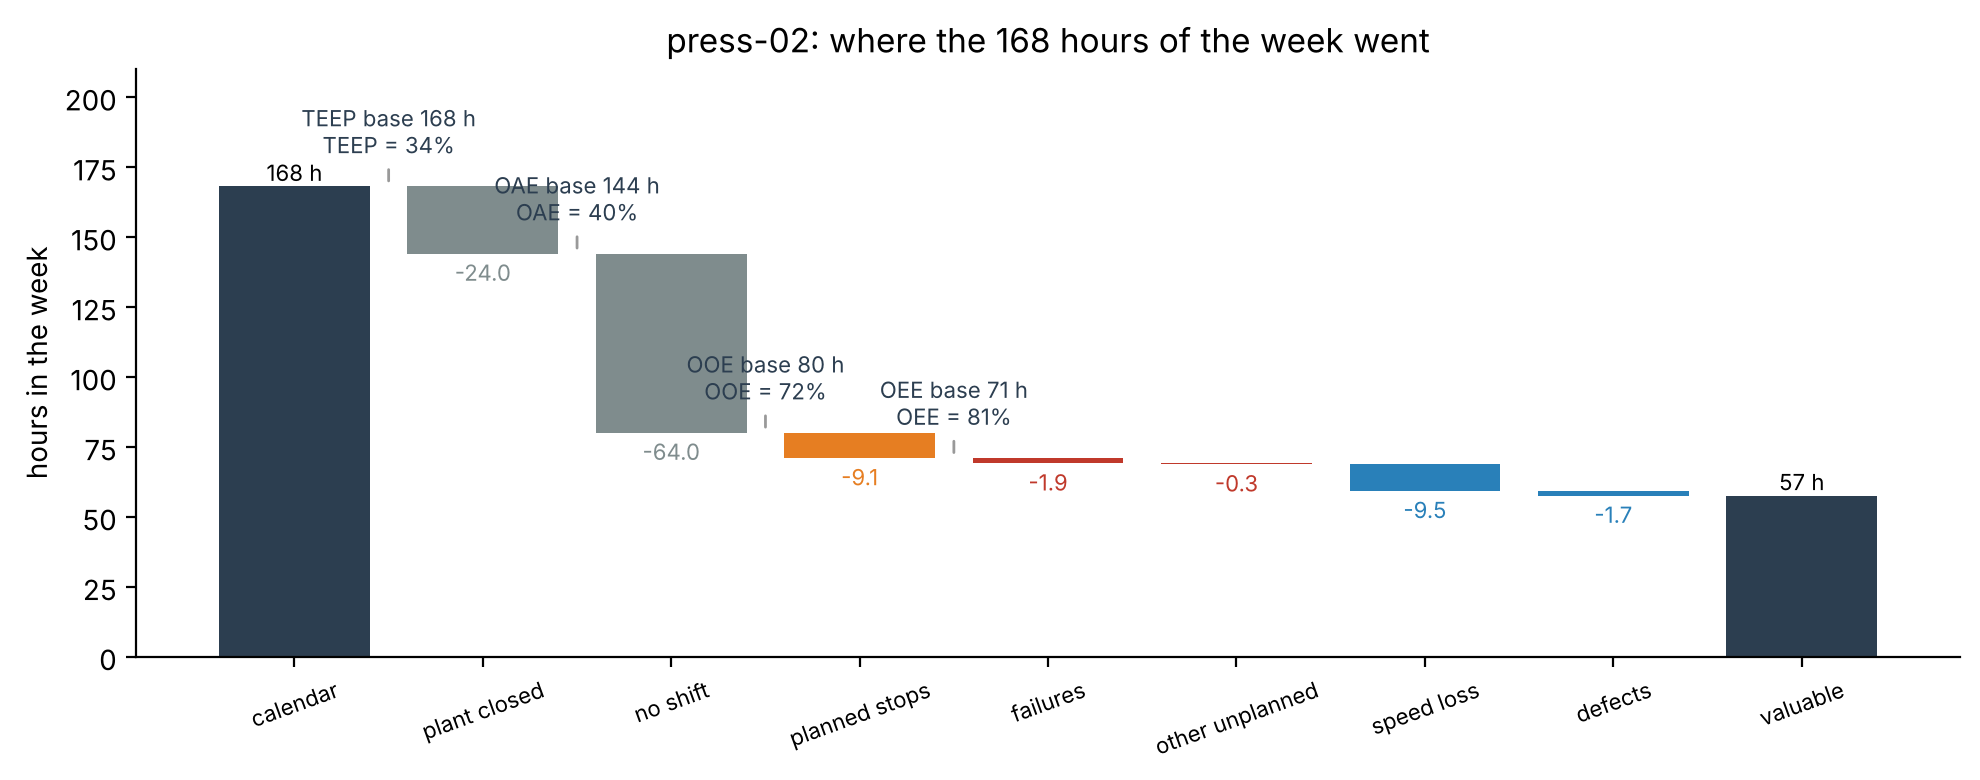

In [7]:
figures.waterfall();

Lendo da esquerda para a direita:

- **OAE para TEEP:** o custo de fechar no domingo.
- **OOE para OAE:** o custo de não ter turno.
- **OEE para OOE:** o custo das paradas planejadas. Almoço e troca de formato não são "perda" para o OEE, mas o OOE mostra quanto eles custam.
- **Abaixo do OEE:** falhas, velocidade e refugo, as perdas clássicas.

## 5. Linha e fábrica: OPE e OFE

O cliente não recebe peças da enchedora, recebe da **saída da linha**. O OPE mede a linha: peças boas que saíram da última máquina, no ritmo da máquina mais lenta, contra o tempo planejado da linha.

In [8]:
r_med, r_ver = lines(medido), lines(verdade)
for k in ("line-1", "line-2", "plant"):
    nome = "OFE (fábrica)" if k == "plant" else f"OPE {k}"
    print(f"{nome:14s} {r_med[k]:6.1%}   verdade {r_ver[k]:6.1%}")
print()
for n in ("filler-01", "capper-01"):
    print(f"OEE {n}: {medido[n].indicator('OEE'):6.1%}")

OPE line-1      79.0%   verdade  79.0%
OPE line-2      81.1%   verdade  81.1%
OFE (fábrica)   79.8%   verdade  79.8%

OEE filler-01:  77.6%
OEE capper-01:  79.0%


**Limite honesto:** nesta simulação as máquinas de uma linha rodam de forma independente. Na vida real, quando a tampadora para, a enchedora enche o pulmão e para também. Modelar esse acoplamento é o próximo passo, e nele o OPE costuma ficar bem abaixo do OEE de cada máquina.

**Outro limite:** OAE, OPE e OFE não têm definição única. Aqui estão escritas as usadas neste repositório. Antes de comparar com outro número, confira a fórmula.

## Erros comuns

- **Chamar toda parada de falha.** O MTBF despenca e o MTTR fica enganoso. Sem categoria, chame de "tempo entre paradas" e não de MTBF.
- **Comparar OEE entre plantas com calendários diferentes.** Uma planta pode ter OEE alto e TEEP baixo só por trabalhar menos turnos.
- **Tirar a preventiva do OEE e esquecer dela.** Ela some do OEE e aparece no OOE. Quem só olha o OEE não vê a preventiva crescendo.
- **Ranquear falhas por contagem.** O que importa é o tempo parado.
- **Somar OEE de máquinas para ter o da linha.** A linha entrega o que sai da última máquina. Use o OPE.

## Confira o que ficou

**1. Por que TEEP ≤ OAE ≤ OOE ≤ OEE sempre?**

<details><summary>Ver resposta</summary>

O numerador é o mesmo e o tempo de referência só diminui de um para o outro, porque cada um tira mais um balde do calendário.

</details>

**2. O que o MTBF calculado sem a categoria da parada mede de verdade?**

<details><summary>Ver resposta</summary>

O tempo médio entre paradas de qualquer tipo. Almoço e troca de formato entram como se fossem quebras.

</details>

**3. A prensa tem OEE de 81 % e TEEP de 34 %. Qual número usar para decidir comprar outra prensa?**

<details><summary>Ver resposta</summary>

O TEEP. Ele mostra que a prensa já existente fica a maior parte da semana sem turno, então há capacidade antes de investir.

</details>

**4. Uma preventiva de 2 h aparece em qual indicador?**

<details><summary>Ver resposta</summary>

Ela fica fora do OEE (é parada planejada) e reduz o OOE, o OAE e o TEEP.

</details>

**5. Por que medir a linha na última máquina?**

<details><summary>Ver resposta</summary>

Porque é o que a linha entrega. Uma máquina boa no meio de uma linha travada não produz nada para o cliente.

</details>

## Exercícios

1. Em `oeelab/week.py`, mude a linha 2 para três turnos (`"ABC"`). O OEE da prensa muda? E o TEEP?
2. Dobre o MTBF da enchedora e veja quanto sobe o OEE da máquina e o OPE da linha 1.
3. Calcule a disponibilidade intrínseca, MTBF ÷ (MTBF + MTTR), de cada máquina e compare com a disponibilidade do OEE. Por que são diferentes?
4. Proponha uma regra para quando o operador não apontar o motivo: a parada vira `unplanned` com `reason` vazio? Que efeito isso tem no MTBF?

## Glossário

- **MTBF:** tempo médio rodando entre duas falhas.
- **MTTR:** tempo médio parado por falha, do início da falha até voltar a rodar.
- **TEEP:** OEE medido contra o calendário inteiro.
- **OOE:** OEE medido contra o tempo com turno, contando as paradas planejadas como perda.
- **OAE:** aqui, medido contra o calendário menos o tempo em que a fábrica estava fechada.
- **OPE:** eficácia da linha medida na saída dela.
- **OFE:** eficácia da fábrica, linhas ponderadas pelo tempo planejado.

## Próximo passo

Dar contexto a esses números: em qual equipamento, com qual ordem e qual lote. Veja o [industrial-ontology-lab](https://github.com/MatheusEduGarcia/industrial-ontology-lab).